In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/Bachelorarbeit/projects'    # folder with your .py modules
OUT     = '/content/drive/MyDrive/vae_results/flatvae/11_08_26'    # where the PDFs go

import os, sys, gc, time
os.chdir(PROJECT); sys.path.insert(0, PROJECT)
os.makedirs(OUT, exist_ok=True)

import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

DEV  = "cuda" if torch.cuda.is_available() else "cpu"
GRID, CHUNK, SEED = 100, 64, 10
print(f"torch {torch.__version__}  train on {DEV}  (diagnostics on cpu)")
if DEV != "cuda":
    print("!! Runtime > Change runtime type > T4 GPU")

from vaediagnostic import run_diagnostics, _np
from datasets import make_torus_dataset, make_plane_dataset, make_plane_dataset_old
try:
    from bin_scripts.sphere_data import make_sphere_dataset_try3
except ModuleNotFoundError as e:
    print(f"!! bin_scripts missing ({e}) -- falling back to a DIFFERENT dataset")
    from datasets import make_sphere_dataset_new as make_sphere_dataset_try3

Mounted at /content/drive
torch 2.11.0+cu128  train on cuda  (diagnostics on cpu)


In [2]:
class simpleVAE(nn.Module):
    def __init__(self, data_dim=2, latent_dim=2, hidden=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(data_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
        )
        self.mu = nn.Linear(hidden, latent_dim)
        self.logvar = nn.Linear(hidden, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, data_dim),
        )

    def encode(self, data):
        h = self.encoder(data)          # one backbone pass, not two
        return self.mu(h), self.logvar(h)

    def reparametrize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, theta):
        return self.decoder(theta)

    def forward(self, data):
        mu, logvar = self.encode(data)
        return self.decode(self.reparametrize(mu, logvar)), mu, logvar


def elbo(x_recon, x, mu, logvar, beta=1.0):
    recon = ((x_recon - x) ** 2).sum(dim=1).mean()
    kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1).mean()
    return recon + beta * kl, recon.item(), kl.item()


def train(epochs=400, lr=1e-3, beta=1.0, dataset=None, device=DEV,
          seed=SEED, log_every=100, eval_every=100, val_n=2000, val_seed=1234):
    if seed is not None:
        torch.manual_seed(seed)

    imgs, angles = dataset()
    data = torch.as_tensor(imgs, dtype=torch.float32, device=device)
    if data.dim() > 2:
        data = data.flatten(1)

    val_imgs, val_ang = dataset(n=val_n, seed=val_seed)
    val = torch.as_tensor(val_imgs, dtype=torch.float32, device=device)
    if val.dim() > 2:
        val = val.flatten(1)

    model = simpleVAE(data_dim=data.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    curve = []
    for ep in range(epochs):
        opt.zero_grad(set_to_none=True)
        x_recon, mu, logvar = model(data)
        loss, r, k = elbo(x_recon, data, mu, logvar, beta)
        loss.backward()
        opt.step()

        if eval_every and (ep % eval_every == 0 or ep == epochs - 1):
            e_tr = per_sample_err(model, data)
            e_va = per_sample_err(model, val)
            curve.append(dict(epoch=ep, loss=loss.item(), recon=r, kl=k,
                              train=e_tr.mean(), val=e_va.mean(),
                              val_median=np.median(e_va),
                              val_p95=np.percentile(e_va, 95)))
            model.train()

        if log_every and (ep % log_every == 0 or ep == epochs - 1):
            print(f"epoch {ep:5d}  loss={loss.item():.4f}  "
                  f"recon={r:.4f}  kl={k:.4f}")

    return model, data, angles, curve, (val, np.asarray(val_ang))

In [3]:
@torch.no_grad()
def _recon(model, x):
    enc = model.encode(x)
    mu = enc[0] if isinstance(enc, tuple) else enc
    return  model.decode(mu)

@torch.no_grad()
def per_sample_err(model, x, batch=4096):
    model.eval()
    p = next(model.parameters())
    x = x.to(device=p.device, dtype=p.dtype)
    return torch.cat([((x[i:i+batch] - _recon(model, x[i:i+batch]))**2).sum(1)
                      for i in range(0, x.shape[0], batch)]).cpu().numpy()

def make_val(data_fn, n=2000, seed=1234):
    p = None
    imgs, ang = data_fn(n=n, seed=seed)
    return torch.as_tensor(imgs, dtype=torch.float32), np.asarray(ang)

def report(name, model, data, val_x, val_ang, n_worst=200, ax_hist=None, ax_map=None):
    e_tr = per_sample_err(model, data)
    e_va = per_sample_err(model, val_x)
    print(f"{name:22s} train {e_tr.mean():.4f}  held-out {e_va.mean():.4f}  "
          f"gap {100*(e_va.mean()/e_tr.mean()-1):5.1f}%   |  held-out "
          f"median {np.median(e_va):.4f}  95th {np.percentile(e_va,95):.4f}  "
          f"max {e_va.max():.4f}  mean/median {e_va.mean()/np.median(e_va):.2f}")

    if ax_hist is not None:
        ax_hist.hist(np.log10(e_va + 1e-12), bins=60, color="0.4")
        ax_hist.axvline(np.log10(np.median(e_va)), color="crimson", lw=1.5)
        ax_hist.set_title(name, fontsize=9)
        ax_hist.set_xlabel(r"$\log_{10}$ per-sample error")

    if ax_map is not None:
        bad = np.argsort(e_va)[-n_worst:]
        ax_map.scatter(val_ang[:, 0], val_ang[:, 1], s=2, c="0.85", linewidths=0)
        ax_map.scatter(val_ang[bad, 0], val_ang[bad, 1], s=6, c="crimson", linewidths=0)
        ax_map.set_aspect("equal")
        ax_map.set_title(f"{name}: worst {n_worst}", fontsize=9)
    return e_tr, e_va

In [4]:
def plot_worst_points(model, data, angles, val_x, val_ang, n_worst=500,
                      n_points=4000, seed=0, s=4, cyclic=True, save=None,
                      panel_labels=("a)", "b)"), label_size=14, show=True):

    e_va = per_sample_err(model, val_x)
    bad = np.argsort(e_va)[-n_worst:]

    with torch.no_grad():
        p = next(model.parameters())
        mu_tr = _np(model.encode(data.to(device=p.device, dtype=p.dtype))[0])
        mu_bad = _np(model.encode(val_x[bad].to(device=p.device, dtype=p.dtype))[0])

    true = _np(angles)
    val_ang = np.asarray(val_ang)

    n = min(n_points, mu_tr.shape[0])
    idx = np.random.default_rng(seed).choice(mu_tr.shape[0], size=n, replace=False)
    mu_tr, true = mu_tr[idx], true[idx]

    if cyclic:
        c_bg, cmap, vmin, vmax = np.mod(true[:, 0], 2*np.pi), "hsv", 0.0, 2*np.pi
    else:
        c_bg, cmap, vmin, vmax = true[:, 0], "viridis", None, None

    fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))

    sc = ax[0].scatter(mu_tr[:, 0], mu_tr[:, 1], s=s, c=c_bg, cmap=cmap,
                       vmin=vmin, vmax=vmax, linewidths=0, alpha=0.75)
    ax[0].scatter(mu_bad[:, 0], mu_bad[:, 1], s=3*s, c="black", linewidths=0,
                  label=f"worst {n_worst} validation")
    ax[0].set_aspect("equal")
    ax[0].set_xlabel(r"$z_1$"); ax[0].set_ylabel(r"$z_2$")
    ax[0].legend(fontsize=12, loc="best")
    fig.colorbar(sc, ax=ax[0], fraction=0.046, pad=0.02,
                 label=r"true $\gamma_1$")

    ax[1].scatter(val_ang[:, 0], val_ang[:, 1], s=2, c="0.85", linewidths=0)
    ax[1].scatter(val_ang[bad, 0], val_ang[bad, 1], s=3*s, c="black",
                  linewidths=0)
    ax[1].set_aspect("equal")
    ax[1].set_xlabel(r"true $\gamma_1$"); ax[1].set_ylabel(r"true $\gamma_2$")

    for a, lab in zip(ax, panel_labels):
        a.text(-0.12, 1.02, lab, transform=a.transAxes, fontsize=label_size,
               fontweight="bold", va="bottom", ha="left")

    fig.tight_layout()
    if save:
        stem, ext = os.path.splitext(save)
        ext = ext or ".pdf"
        fig.savefig(f"{stem}_worst{ext}", dpi=150, bbox_inches="tight")
    if not show:
        plt.close(fig)

    print(f"worst {n_worst}: err {e_va[bad].min():.3f}..{e_va[bad].max():.3f}   "
          f"median all {np.median(e_va):.3f}   "
          f"they carry {100*e_va[bad].sum()/e_va.sum():.1f}% of total error")
    return fig, bad, e_va

In [5]:
import pandas as pd

def run(fname, dataset, epochs, cyclic, label):
    print(f"\n=== {fname}  ({label})")
    t0 = time.time()
    model, data, angles, curve, (val_x, val_ang) = train(epochs=epochs, dataset=dataset)
    print(f"    trained in {time.time()-t0:.0f}s")

    # curvature_map hardcodes device="cpu"; move both back so nothing
    # inside it lands on a mismatched device
    model, data = model.cpu(), data.cpu()

    out = os.path.join(OUT, fname)
    figs = run_diagnostics(model, data, angles, grid=GRID, chunk=CHUNK,
                           fname=out, cyclic=cyclic)
    stem, ext = os.path.splitext(out); ext = ext or ".pdf"
    print(f"    wrote {os.path.basename(stem)}_latent{ext} and "
          f"{os.path.basename(stem)}_curvature{ext}")
    print(f"    done in {time.time()-t0:.0f}s")
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return model, data, angles, curve, (val, np.asarray(val_ang))


In [ ]:
def plot_curve(curve, fname, title=None, panel_labels=("a)", "b)"),
               label_size=14, show=True):
    c = pd.DataFrame(curve)
    stem, ext = os.path.splitext(fname)
    ext = ext or ".pdf"

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

    ax[0].plot(c.epoch, c.train, label="train", color="0.3")
    ax[0].plot(c.epoch, c.val, label="validation mean", color="crimson")
    ax[0].plot(c.epoch, c.val_median, "--", label="validation median",
               color="crimson", alpha=0.6)
    ax[0].set_yscale("log")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("reconstruction error")
    ax[0].legend(fontsize=12)

    ax[1].plot(c.epoch, c.val / c.train, color="0.3", label=" / train")
    ax[1].plot(c.epoch, c.val / c.val_median, color="steelblue",
               label="mean / median (validation)")
    ax[1].axhline(1.0, color="0.7", lw=1)
    ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("ratio")
    ax[1].legend(fontsize=12)

    for a, lab in zip(ax, panel_labels):
        a.text(-0.12, 1.02, lab, transform=a.transAxes, fontsize=label_size,
               fontweight="bold", va="bottom", ha="left")
    if title:
        fig.suptitle(title, fontsize=10)

    fig.tight_layout()
    fig.savefig(f"{stem}_traincurve{ext}", dpi=150, bbox_inches="tight")
    c.to_csv(f"{stem}_traincurve.csv", index=False)
    if not show:
        plt.close(fig)
    return fig, c


=== flat on flat  (flat plane)
epoch     0  loss=53.1925  recon=53.1701  kl=0.0224
epoch   100  loss=9.9248  recon=8.6332  kl=1.2916
epoch   200  loss=5.7556  recon=3.3953  kl=2.3603
epoch   300  loss=4.7634  recon=2.1722  kl=2.5913
epoch   400  loss=4.2578  recon=1.5167  kl=2.7411
epoch   500  loss=4.1057  recon=1.3287  kl=2.7770
epoch   600  loss=4.0166  recon=1.2184  kl=2.7982
epoch   700  loss=4.0090  recon=1.1972  kl=2.8118
epoch   800  loss=3.9439  recon=1.1273  kl=2.8166
epoch   900  loss=3.9319  recon=1.1187  kl=2.8132
epoch  1000  loss=3.9114  recon=1.0925  kl=2.8189
epoch  1100  loss=3.8949  recon=1.0684  kl=2.8265
epoch  1200  loss=3.8992  recon=1.0799  kl=2.8194
epoch  1300  loss=3.9020  recon=1.0824  kl=2.8196
epoch  1400  loss=3.8966  recon=1.0776  kl=2.8190
epoch  1500  loss=3.8573  recon=1.0323  kl=2.8250
epoch  1600  loss=3.8692  recon=1.0393  kl=2.8299
epoch  1700  loss=3.8805  recon=1.0473  kl=2.8332
epoch  1800  loss=3.8636  recon=1.0357  kl=2.8279
epoch  1900  los

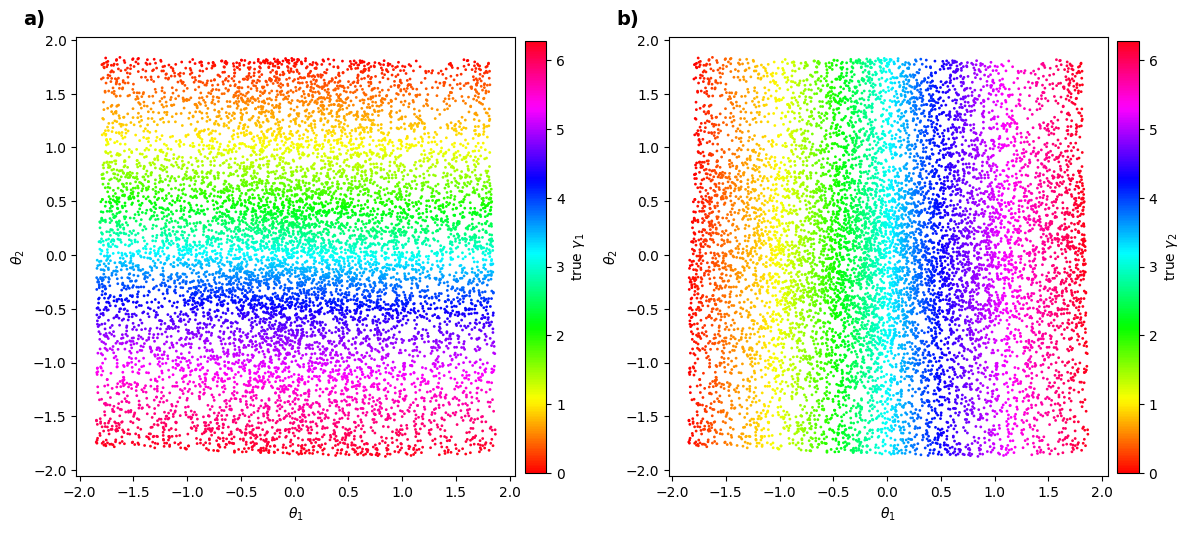

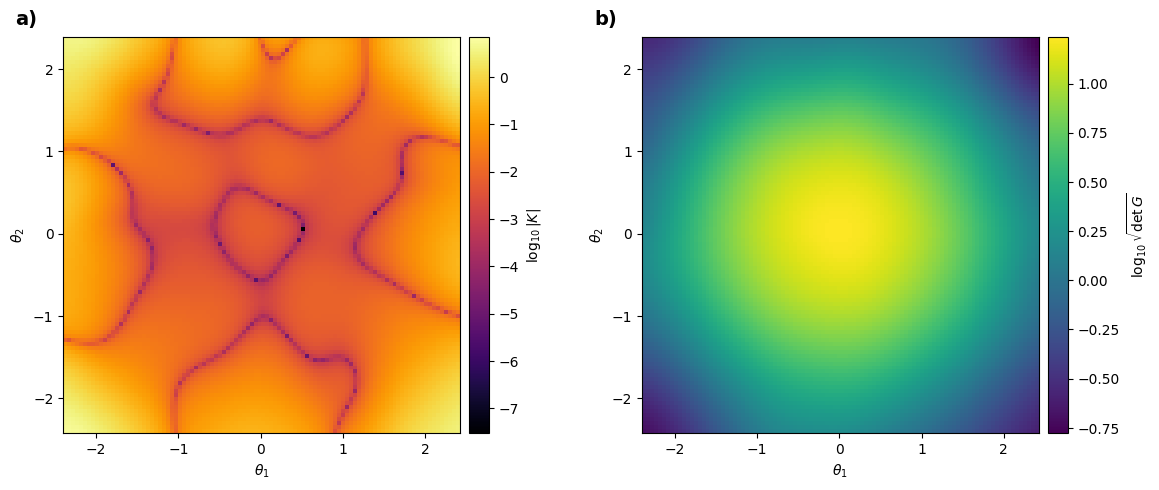

In [56]:
model, data, angles, curve, (val_x, val_ang) = run("flat on flat", make_plane_dataset_old, 10000, (True, True), "flat plane")


     epoch      loss     recon        kl     train       val  val_median  \
98    9800  3.835051  0.978431  2.856619  0.072228  0.073632    0.040235   
99    9900  3.822133  0.994257  2.827876  0.073285  0.074574    0.034554   
100   9999  3.814515  0.955343  2.859172  0.071046  0.072241    0.030378   

      val_p95  
98   0.291472  
99   0.300197  
100  0.309125  
worst 200: err 0.218..0.683   median all 0.030   they carry 45.2% of total error


(<Figure size 1200x550 with 3 Axes>,
 array([1696, 1313, 1387,  114, 1637,  300, 1414,  964,  660, 1566,  169,
         693, 1097, 1049, 1787,  812,  209, 1627,  121, 1468, 1231, 1701,
           0, 1583,   91,  874,  260, 1451,  744, 1420,  621, 1496, 1495,
         553,  966,  674,  869, 1786,   12,  264, 1128, 1652,  834, 1296,
         737,  302,  109,  973, 1593, 1314,   21, 1582,  235, 1174,  939,
        1319,  129,  345,  745, 1284,  601,  951,  738, 1548,  897,  383,
        1117, 1419,  298, 1553, 1373, 1954, 1150, 1771, 1054, 1425,  417,
        1153,  544,  373, 1159, 1025,  582, 1519, 1454,  460,  551, 1294,
         752, 1638,  889,  845,  665,  769, 1043,  177,  866, 1551,  393,
        1152, 1180, 1809, 1793, 1315,   82,  875, 1597, 1381, 1647, 1161,
        1474,  204, 1120,  502,  131, 1093,  726, 1167, 1599, 1769,  307,
        1210,   17,  642, 1494, 1746, 1604, 1752,  148,  337, 1447,  468,
         561,   96, 1639, 1023, 1879,   87, 1684,   14,  851, 1145,  429,
 

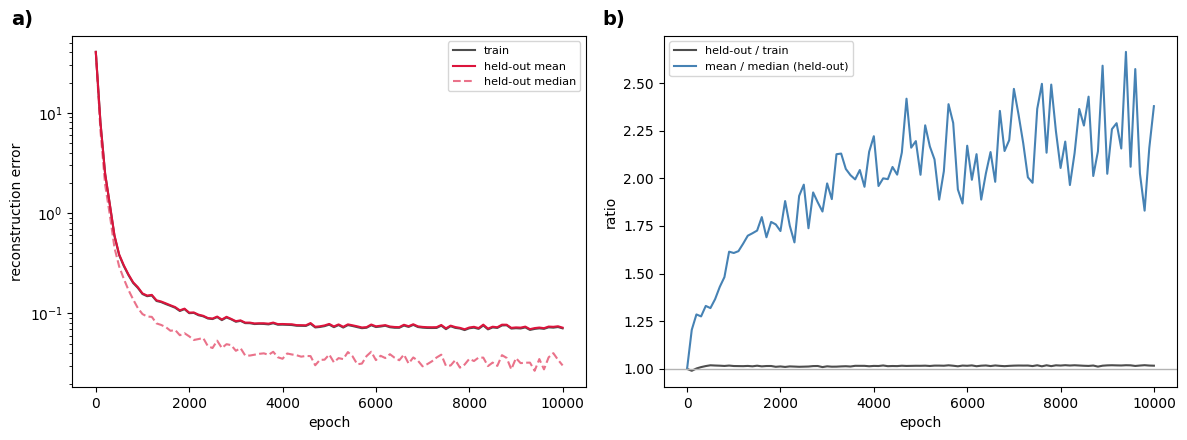

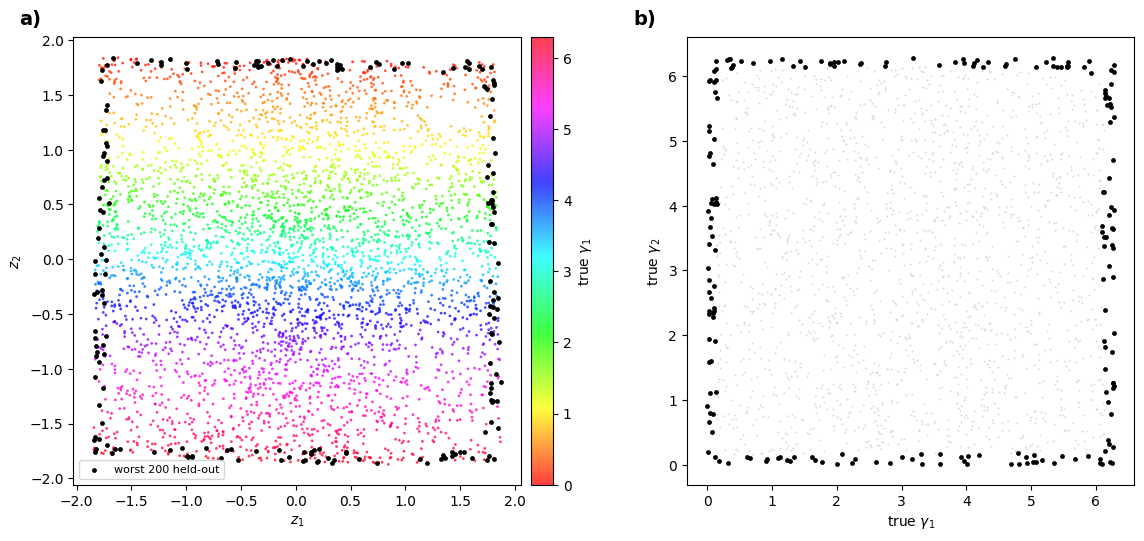

In [42]:
fig, c = plot_curve(curve, os.path.join(OUT, "flat on flat"))
print(c.tail(3))
plot_worst_points(model, data, angles, val_x, val_ang,
                  save=os.path.join(OUT, "flat on flat"))


=== border flat on flat  (bordered flat plane)
epoch     0  loss=48.9592  recon=48.9473  kl=0.0119
epoch   100  loss=19.3015  recon=17.6843  kl=1.6171
epoch   200  loss=15.5034  recon=12.5986  kl=2.9048
epoch   300  loss=14.1521  recon=10.8634  kl=3.2887
epoch   400  loss=12.8011  recon=9.0363  kl=3.7648
epoch   500  loss=11.6794  recon=7.6289  kl=4.0506
epoch   600  loss=10.5631  recon=6.2978  kl=4.2653
epoch   700  loss=10.0032  recon=5.6874  kl=4.3158
epoch   800  loss=9.2611  recon=4.8444  kl=4.4166
epoch   900  loss=8.5271  recon=4.0162  kl=4.5109
epoch  1000  loss=7.9426  recon=3.3586  kl=4.5839
epoch  1100  loss=7.5906  recon=2.9721  kl=4.6185
epoch  1200  loss=7.3626  recon=2.7333  kl=4.6293
epoch  1300  loss=7.2033  recon=2.5685  kl=4.6348
epoch  1400  loss=7.0632  recon=2.4250  kl=4.6382
epoch  1500  loss=6.9207  recon=2.2722  kl=4.6485
epoch  1600  loss=6.8391  recon=2.1720  kl=4.6671
epoch  1700  loss=6.7671  recon=2.1014  kl=4.6657
epoch  1800  loss=6.6512  recon=1.9758  

(<Figure size 1200x550 with 3 Axes>,
 array([ 487,  214, 1754, 1731,  650,  525, 1357, 1831, 1161, 1606,  565,
        1145,  108, 1892, 1430,  537,  331,  255,  360,  490,  624,  596,
          46, 1460, 1670,  594,  304, 1922, 1618, 1186,  968,  177, 1048,
         282,  424,  781, 1516, 1042, 1664,  834, 1783,  683,  563,  783,
        1085, 1484,  189, 1057,  886,  259, 1534,  260,  397,  241, 1206,
        1799,  673, 1778, 1360,   12,  605, 1004, 1622, 1601, 1919, 1727,
         231, 1889, 1647, 1235,  939,   53,  160, 1479,  881,   24,  369,
         382, 1066, 1200, 1956,  466,  329, 1149, 1833,  625, 1862,  767,
         949,  158, 1441, 1143,  507,  875, 1097, 1381,  955, 1769, 1784,
        1112,  688,  344, 1871, 1110, 1699,  142, 1554, 1038,   40,  694,
        1439,  506,  461, 1237,  632, 1044, 1147,  562, 1470, 1049, 1873,
          18, 1347,  887,  584, 1413,  188, 1526,  465,  226,  824,  615,
        1634,  711, 1400, 1407,  670,  642,   67, 1779,  674, 1295,  318,
 

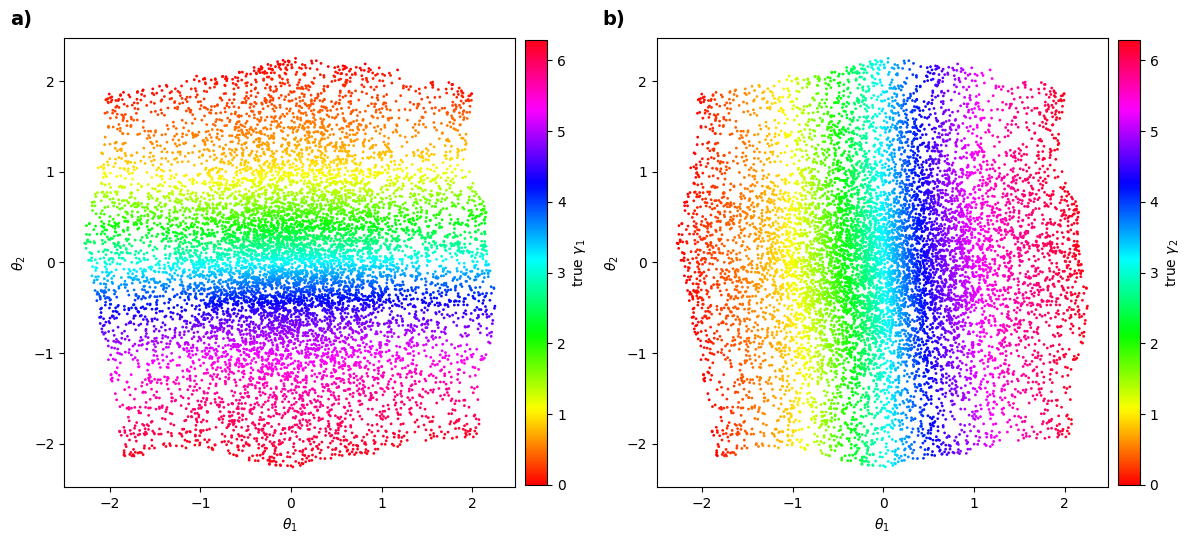

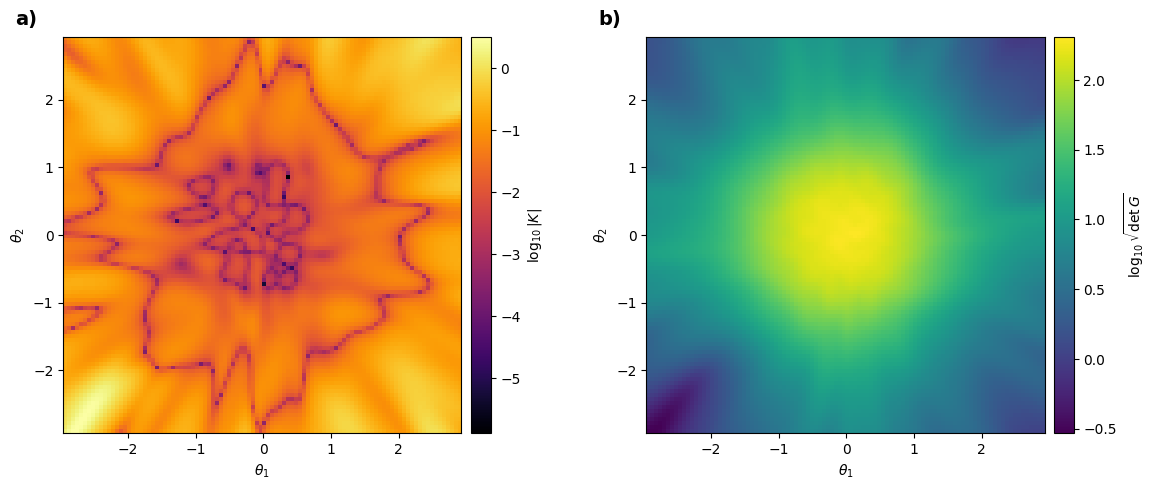

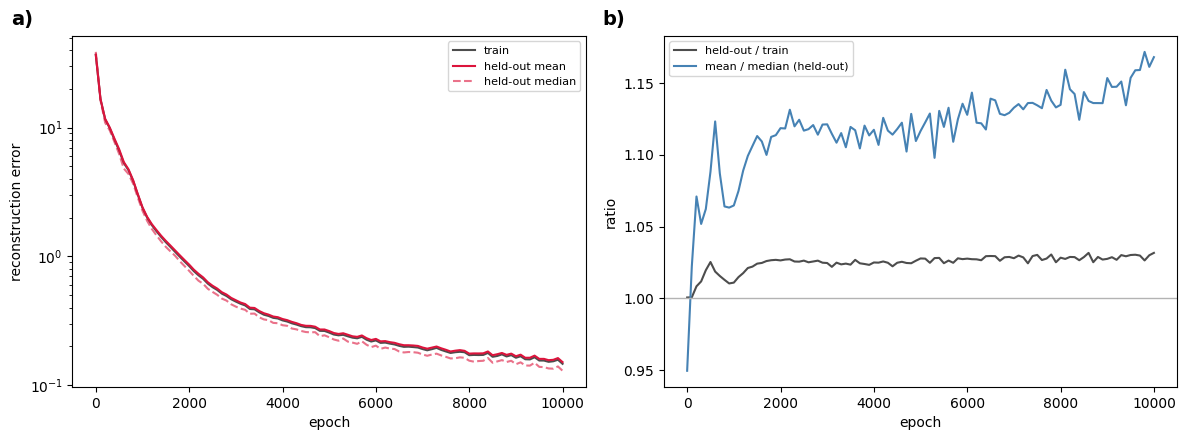

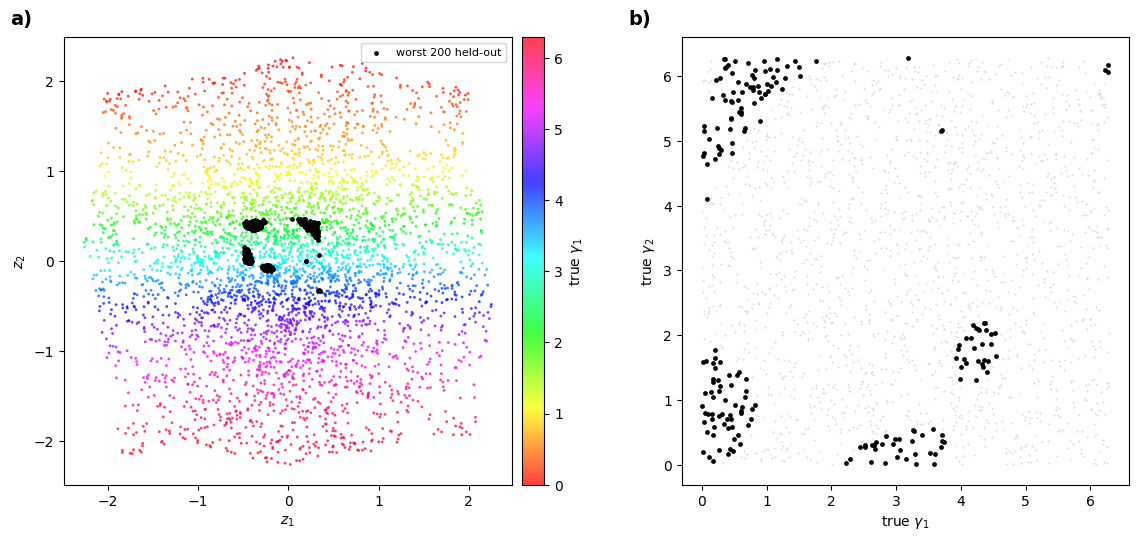

In [48]:
model, data, angles, curve, (val_x, val_ang) = run("border flat on flat", make_plane_dataset, 10000, (True, True), "bordered flat plane")
fig, c = plot_curve(curve, os.path.join(OUT, "border flat on flat"))
print(c.tail(3))
plot_worst_points(model, data, angles, val_x, val_ang,
                  save=os.path.join(OUT, "border flat on flat"))



=== torus on flat  (torus)
epoch     0  loss=52.1704  recon=52.1580  kl=0.0124
epoch   100  loss=21.3402  recon=19.5669  kl=1.7733
epoch   200  loss=18.0384  recon=15.2121  kl=2.8264
epoch   300  loss=16.0959  recon=12.6875  kl=3.4084
epoch   400  loss=14.8079  recon=11.0172  kl=3.7906
epoch   500  loss=13.8302  recon=9.8291  kl=4.0011
epoch   600  loss=12.9968  recon=8.8513  kl=4.1455
epoch   700  loss=12.1555  recon=7.8387  kl=4.3168
epoch   800  loss=11.2804  recon=6.8287  kl=4.4517
epoch   900  loss=10.7069  recon=6.1663  kl=4.5406
epoch  1000  loss=10.2293  recon=5.6238  kl=4.6055
epoch  1100  loss=9.8174  recon=5.1557  kl=4.6618
epoch  1200  loss=9.4610  recon=4.7540  kl=4.7070
epoch  1300  loss=9.1770  recon=4.4242  kl=4.7527
epoch  1400  loss=8.8917  recon=4.1096  kl=4.7822
epoch  1500  loss=8.6039  recon=3.7882  kl=4.8157
epoch  1600  loss=8.4346  recon=3.5812  kl=4.8534
epoch  1700  loss=8.2602  recon=3.3965  kl=4.8637
epoch  1800  loss=8.1006  recon=3.2121  kl=4.8885
epoch 

(<Figure size 1200x550 with 3 Axes>,
 array([1626, 1032, 1271,  764,  498, 1297,  768, 1508,   93,  938, 1788,
         101,  967, 1755, 1204,  445,  615,  531, 1257, 1855,  790, 1044,
         639, 1765,  785,   17, 1212, 1618,   25,  601, 1183,  513,  389,
        1824, 1767, 1456,  567,  320,  616, 1295,  779, 1286, 1037, 1801,
        1763, 1615, 1544, 1345, 1110,  377,  118, 1693, 1600,  352, 1413,
         955,  518,  212,  112, 1663,  293,  831, 1591, 1048,  278, 1403,
         565,  269, 1914,  700, 1721,  863,  474,  452,  815,  724,  875,
         393, 1613,  895,  958, 1480, 1542, 1199, 1487,  509, 1067,  490,
        1327, 1102,  820,  715,   85,  893,  280, 1240,  258,  990, 1799,
         709,  411, 1944, 1569, 1692,  834,  298, 1486, 1706,   18, 1172,
        1049,  281,  442,  992, 1000,  710, 1523, 1003, 1953,  295, 1543,
         136,  883,  693, 1120, 1512,  488, 1268, 1162, 1986, 1314, 1095,
        1779,  398,  747,   89,  415,  726, 1657,  255,  664,  479, 1622,
 

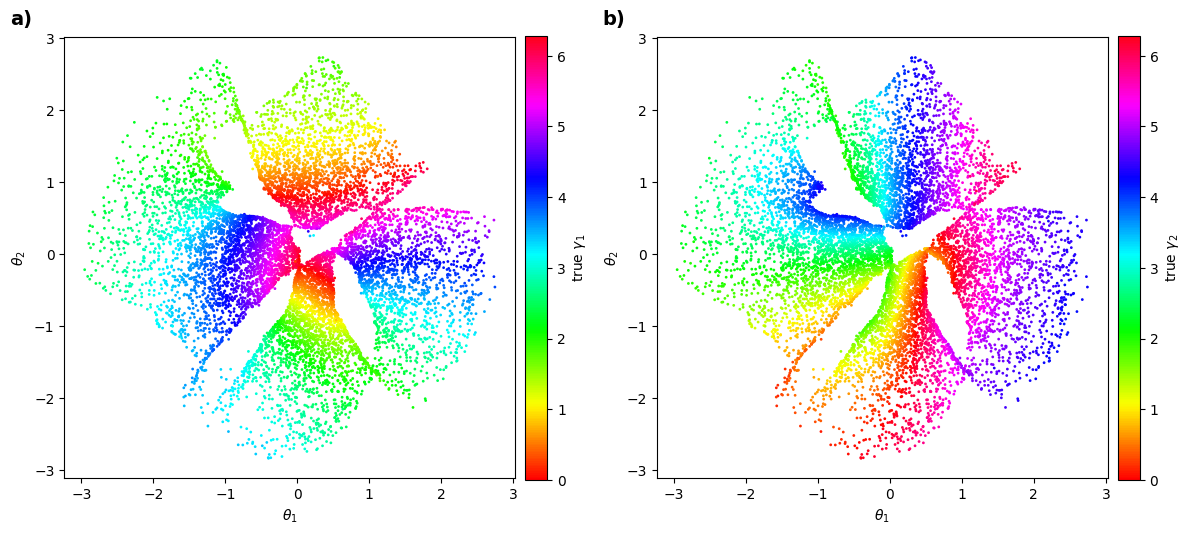

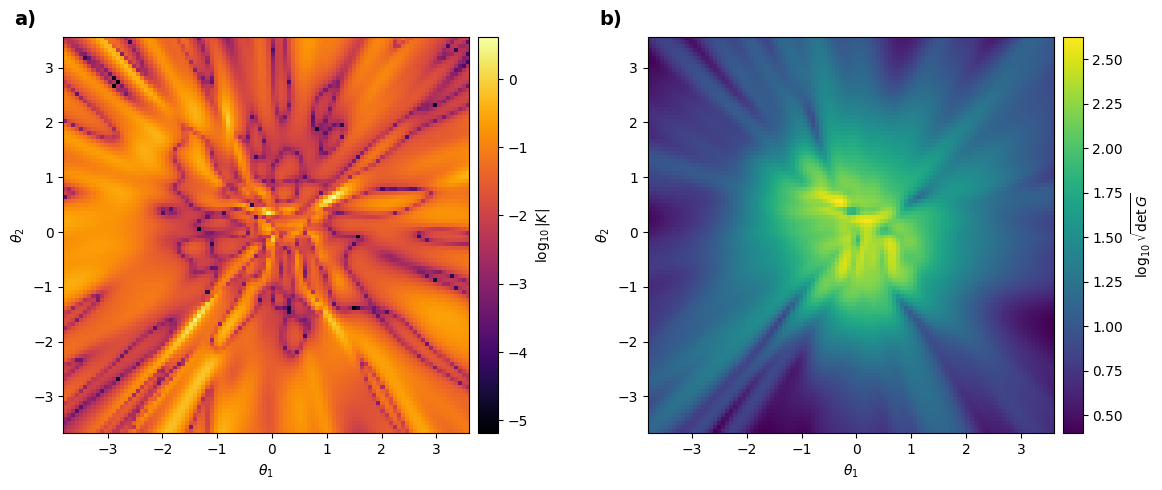

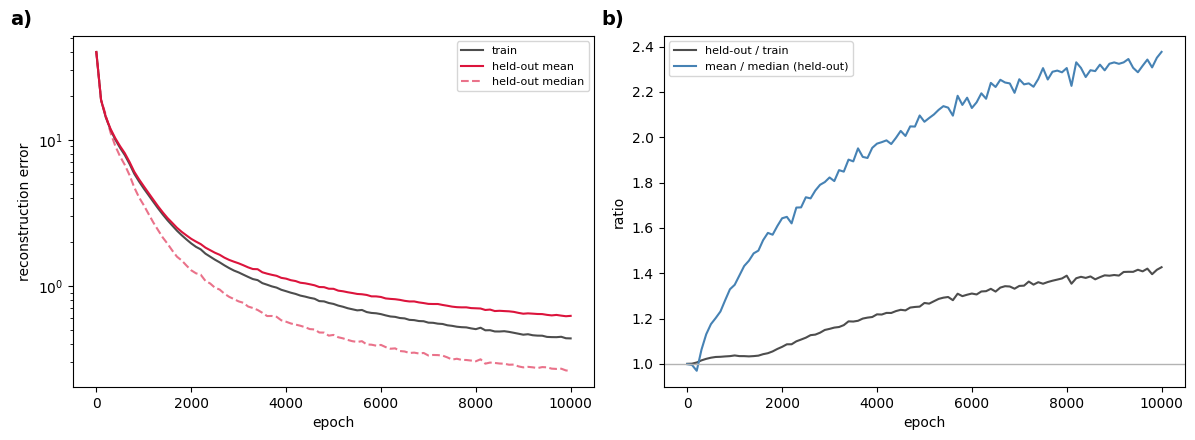

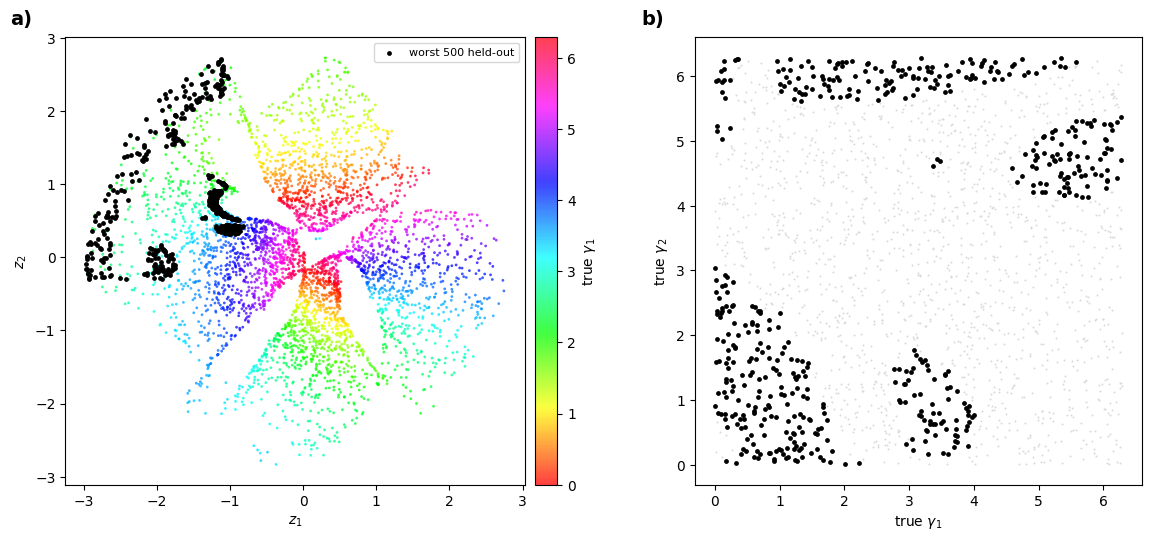

In [54]:
model, data, angles, curve, (val_x, val_ang) = run("torus on flat", make_torus_dataset, 10000, (True, True), "torus")
fig, c = plot_curve(curve, os.path.join(OUT, "torus on flat"))
print(c.tail(3))
plot_worst_points(model, data, angles, val_x, val_ang,
                  save=os.path.join(OUT, "torus on flat"))



=== sphere on flat  (sphere)
epoch     0  loss=45.8264  recon=45.8149  kl=0.0114
epoch   100  loss=17.7638  recon=16.8049  kl=0.9588
epoch   200  loss=15.6333  recon=14.3333  kl=1.3000
epoch   300  loss=15.0977  recon=13.5833  kl=1.5144
epoch   400  loss=13.4581  recon=11.0219  kl=2.4362
epoch   500  loss=12.7081  recon=9.8834  kl=2.8247
epoch   600  loss=12.3096  recon=9.3076  kl=3.0020
epoch   700  loss=11.9987  recon=8.8348  kl=3.1639
epoch   800  loss=11.7416  recon=8.5039  kl=3.2377
epoch   900  loss=11.4925  recon=8.1677  kl=3.3248
epoch  1000  loss=10.8932  recon=7.3261  kl=3.5671
epoch  1100  loss=10.1224  recon=6.3503  kl=3.7720
epoch  1200  loss=9.3890  recon=5.4279  kl=3.9611
epoch  1300  loss=8.7232  recon=4.6153  kl=4.1079
epoch  1400  loss=8.2559  recon=4.0468  kl=4.2091
epoch  1500  loss=7.9203  recon=3.6443  kl=4.2759
epoch  1600  loss=7.6847  recon=3.3462  kl=4.3385
epoch  1700  loss=7.4963  recon=3.1240  kl=4.3723
epoch  1800  loss=7.2996  recon=2.8719  kl=4.4277
epo

NameError: name 'val' is not defined

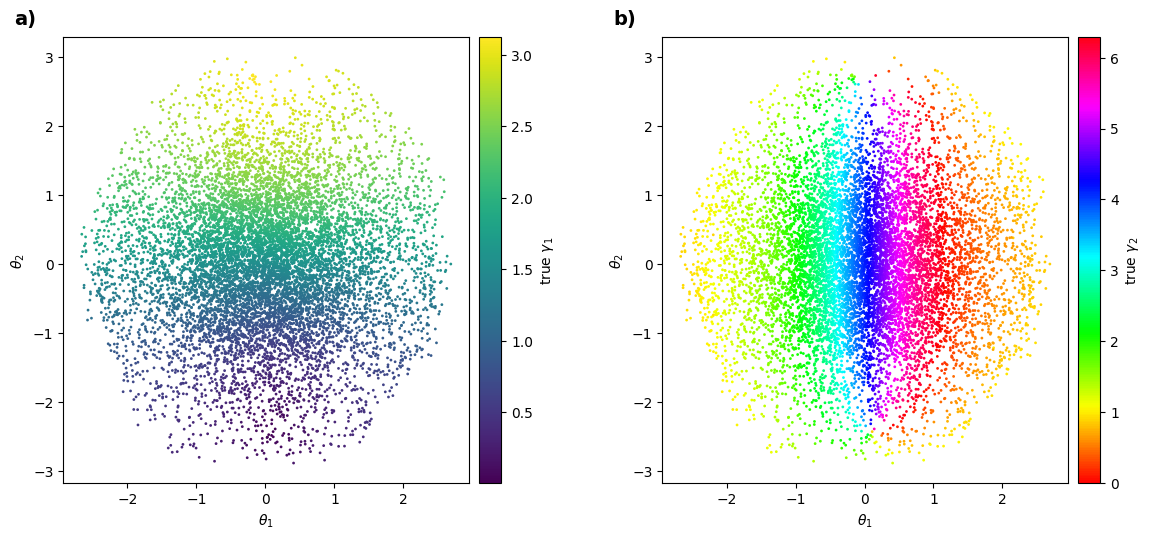

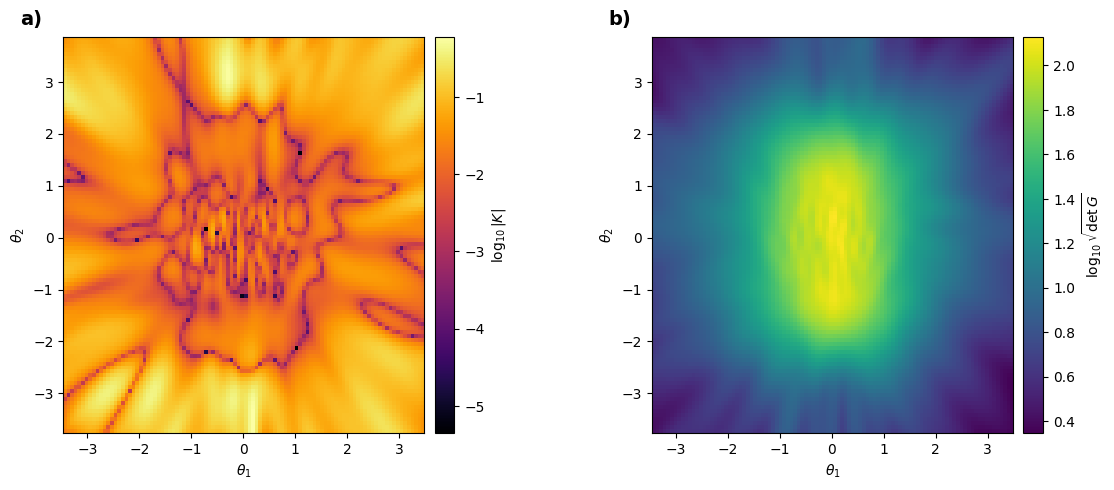

In [7]:
model, data, angles, curve, (val_x, val_ang) = run("sphere on flat", make_sphere_dataset_try3, 10000, (False, True), "sphere")
fig, c = plot_curve(curve, os.path.join(OUT, "sphere on flat"))
print(c.tail(3))
plot_worst_points(model, data, angles, val_x, val_ang,
                  save=os.path.join(OUT, "sphere on flat"))

     epoch      loss     recon        kl     train       val  val_median  \
98    9800  5.996305  1.259562  4.736743  0.261893  0.318378    0.246762   
99    9900  5.978446  1.256366  4.722080  0.255211  0.312633    0.244322   
100   9999  5.975714  1.227298  4.748416  0.246425  0.295582    0.233020   

      val_p95  
98   0.436166  
99   0.415304  
100  0.406027  


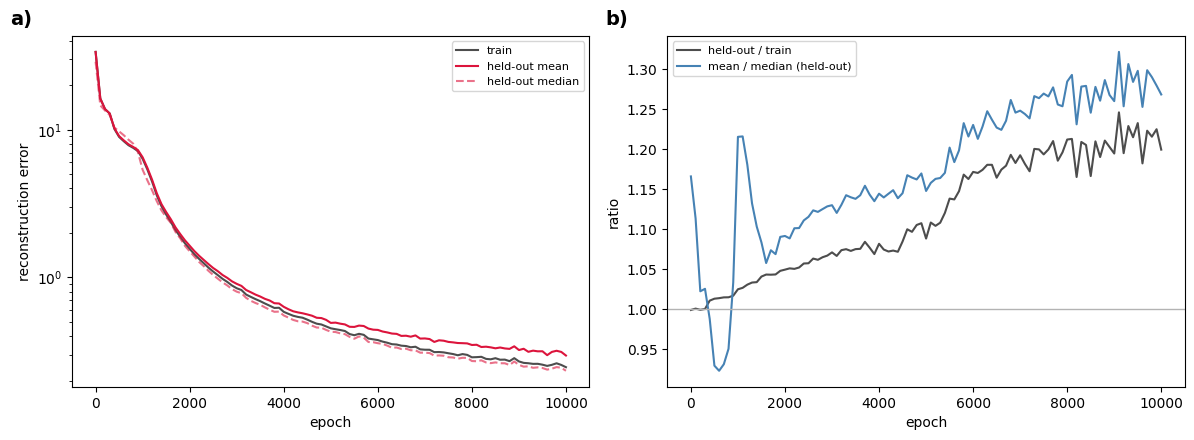

In [51]:
fig, c = plot_curve(curve, os.path.join(OUT, "sphere on flat"))
print(c.tail(3))


=== sphere on flat small 1  (sphere)
epoch     0  loss=45.8264  recon=45.8149  kl=0.0114
epoch   100  loss=17.7638  recon=16.8049  kl=0.9588
epoch   200  loss=15.6333  recon=14.3333  kl=1.3000
epoch   300  loss=15.0977  recon=13.5833  kl=1.5144
epoch   400  loss=13.4581  recon=11.0219  kl=2.4362
epoch   500  loss=12.7081  recon=9.8834  kl=2.8247
epoch   600  loss=12.3096  recon=9.3076  kl=3.0020
epoch   700  loss=11.9987  recon=8.8348  kl=3.1639
epoch   749  loss=11.8587  recon=8.6525  kl=3.2062
    trained in 4s
  |K|  : median 6.476e-03   max 1.571e-01
  sqrt(det g): median 8.259e+00   max 1.761e+01
    wrote sphere on flat small 1_latent.pdf and sphere on flat small 1_curvature.pdf
    done in 21s

=== sphere on flat mall 2  (sphere)
epoch     0  loss=45.8264  recon=45.8149  kl=0.0114
epoch   100  loss=17.7638  recon=16.8049  kl=0.9588
epoch   200  loss=15.6333  recon=14.3333  kl=1.3000
epoch   300  loss=15.0977  recon=13.5833  kl=1.5144
epoch   400  loss=13.4581  recon=11.0219  kl

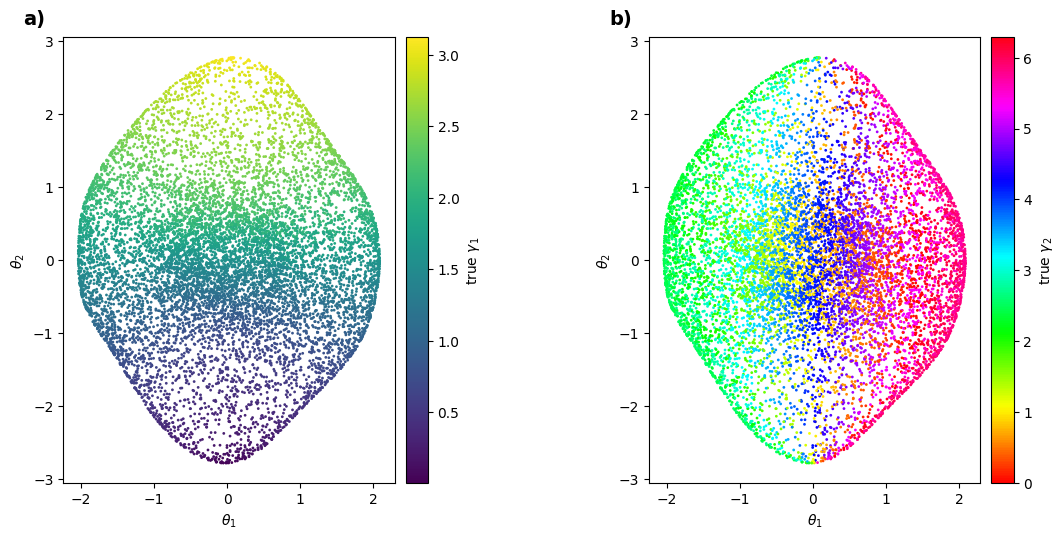

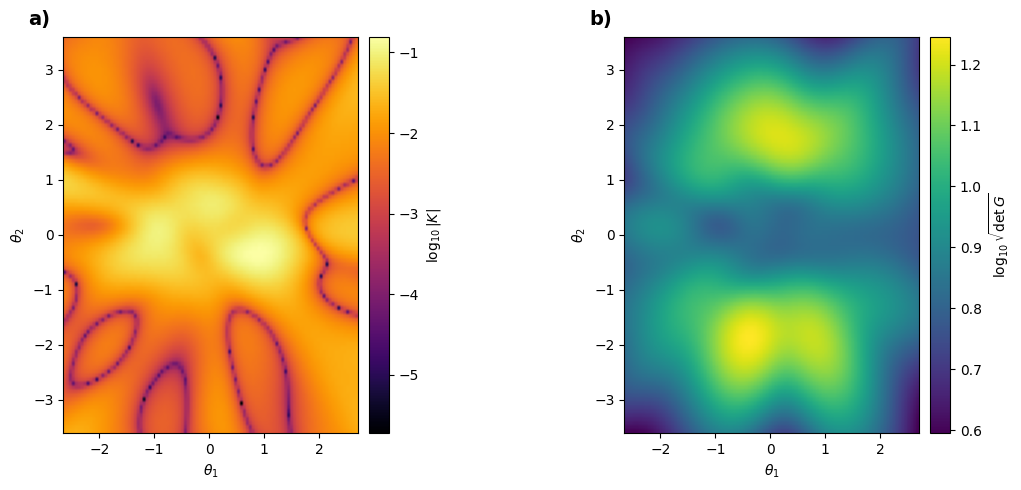

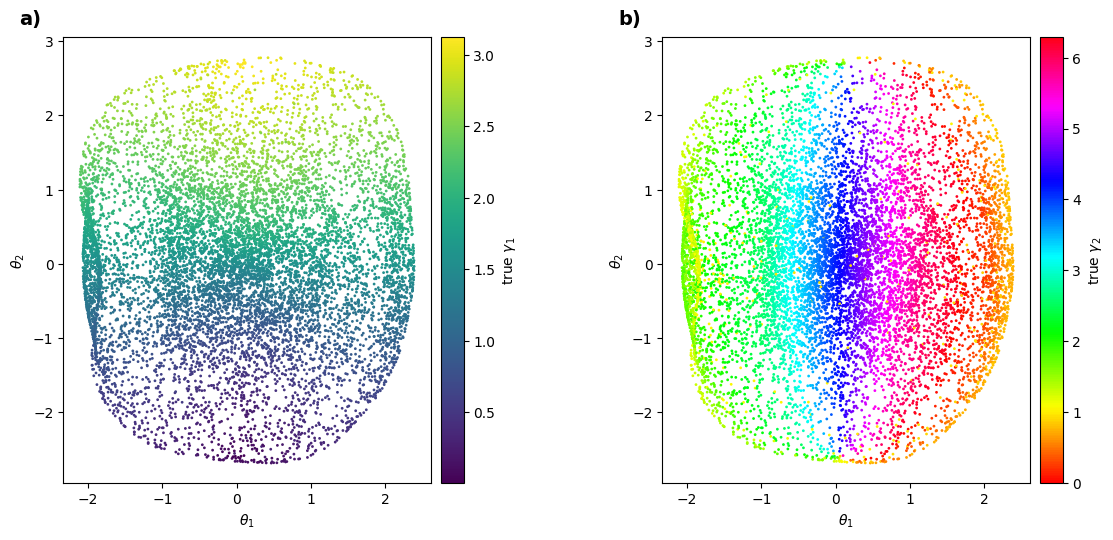

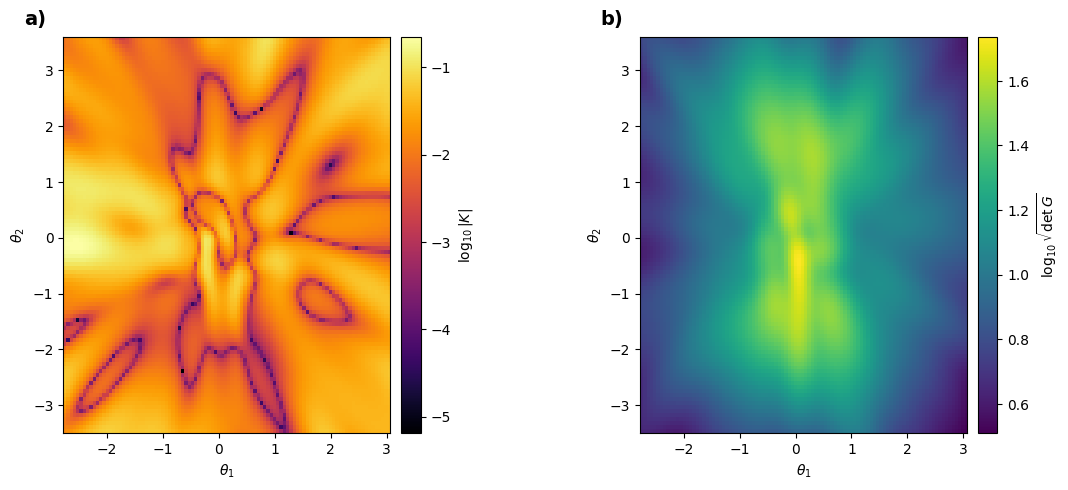

In [52]:
model, data, angles, figs, curve = run("sphere on flat small 1", make_sphere_dataset_try3, 750, (False, True), "sphere")
model, data, angles, figs, curve = run("sphere on flat mall 2", make_sphere_dataset_try3, 1250, (False, True), "sphere")
